**Part A: Tabular Data (Pima Indians Diabetes)**

In [13]:
# SECTION 1: SETUP AND DATA ACQUISITION

# 1.1 Import Core Scientific, Statistical, and Preprocessing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

# Configure runtime visualization and data formatting
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1.2 Ingest and Inspect Raw Clinical Records

# Load dataset from a reliable public URL to avoid FileNotFoundError
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, names=column_names)

print("--- SECTION 1: DATA INSPECTION ---")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Data Types & Non-Null Values:")
print(df.info())

print("\nDescriptive Summary of Numeric Features:")
print(df.describe().T[['min', 'mean', '50%', 'max']])

--- SECTION 1: DATA INSPECTION ---
Dataset Shape: 768 rows, 9 columns

Data Types & Non-Null Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Descriptive Summary of Numeric Features:
                             min        mean       50%     max
Pregnancies                0.

In [14]:
# SECTION 2: CLINICAL DATA CLEANING (PHYSIOLOGICAL BOUNDARIES)

# 2.1 Identify Biologically Impossible Zeros (Medical Inconsistency Audit)
# Living humans cannot survive with 0 blood pressure, glucose, BMI, or skinfold thickness
implausible_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("\n--- SECTION 2: CLINICAL AUDIT FOR IMPLAUSIBLE ZEROES ---")
for col in implausible_zero_cols:
    zero_count = (df[col] == 0).sum()
    pct = (zero_count / len(df)) * 100
    print(f"{col:<15}: {zero_count:>3} zeros ({pct:>5.2f}%)")

# 2.2 Convert Invalid Zero Values to NaN (Explicit Missingness)
df_clean = df.copy()
df_clean[implausible_zero_cols] = df_clean[implausible_zero_cols].replace(0, np.nan)

print("\nConfirmed NaN Counts Post-Replacement:")
print(df_clean[implausible_zero_cols].isnull().sum())


--- SECTION 2: CLINICAL AUDIT FOR IMPLAUSIBLE ZEROES ---
Glucose        :   5 zeros ( 0.65%)
BloodPressure  :  35 zeros ( 4.56%)
SkinThickness  : 227 zeros (29.56%)
Insulin        : 374 zeros (48.70%)
BMI            :  11 zeros ( 1.43%)

Confirmed NaN Counts Post-Replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [15]:
# SECTION 3: FEATURE ENGINEERING & CLINICAL CATEGORIZATION

# 3.1 Derive WHO-Standard BMI Risk Categories
# Bins: Underweight (<18.5), Normal (18.5-24.9), Overweight (25-29.9), Obese (>=30)
df_clean['BMI_Category'] = pd.cut(
    df_clean['BMI'],
    bins=[0, 18.5, 24.9, 29.9, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

# 3.2 Age Stratification for Epidemiological Grouping
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[20, 30, 40, 50, 100],
    labels=['21-30', '31-40', '41-50', '50+']
)

# 3.3 Clinical Risk Binary Indicators
# Diastolic Blood Pressure >= 80 mmHg flags Stage 1/2 Hypertension
df_clean['High_BP'] = (df_clean['BloodPressure'] >= 80).astype(int)

# Fasting Glucose >= 126 mg/dL meets standard clinical diagnostic criteria for diabetes
df_clean['Elevated_Fasting_Glucose'] = (df_clean['Glucose'] >= 126).astype(int)

print("\n--- SECTION 3: DERIVED CLINICAL FEATURES (PREVIEW) ---")
print(df_clean[['BMI', 'BMI_Category', 'Age', 'Age_Group', 'BloodPressure', 'High_BP']].head())


--- SECTION 3: DERIVED CLINICAL FEATURES (PREVIEW) ---
    BMI BMI_Category  Age Age_Group  BloodPressure  High_BP
0  33.6        Obese   50     41-50           72.0        0
1  26.6   Overweight   31     31-40           66.0        0
2  23.3       Normal   32     31-40           64.0        0
3  28.1   Overweight   21     21-30           66.0        0
4  43.1        Obese   33     31-40           40.0        0


In [16]:
# SECTION 4: STATISTICAL HYPOTHESIS TESTING
alpha = 0.05

# 4.1 Independent Two-Sample t-Test (Serum Glucose vs Diabetes Outcome)
# H0: Population mean glucose is equal between diabetic and non-diabetic cohorts
# H1: Population mean glucose differs significantly between the two cohorts
diabetic_glucose = df_clean[df_clean['Outcome'] == 1]['Glucose'].dropna()
non_diabetic_glucose = df_clean[df_clean['Outcome'] == 0]['Glucose'].dropna()

# Welch's t-test (equal_var=False) is used to avoid assuming equal variances
t_stat, p_val_t = stats.ttest_ind(diabetic_glucose, non_diabetic_glucose, equal_var=False)

print("\n" + "="*70)
print("SECTION 4.1: INDEPENDENT TWO-SAMPLE t-TEST (WELCH'S)")
print("="*70)
print(f"Diabetic Cohort Mean:     {diabetic_glucose.mean():.2f} mg/dL (n={len(diabetic_glucose)})")
print(f"Non-Diabetic Cohort Mean: {non_diabetic_glucose.mean():.2f} mg/dL (n={len(non_diabetic_glucose)})")
print(f"t-statistic: {t_stat:.4f} | p-value: {p_val_t:.4e}")
if p_val_t < alpha:
    print("Decision: Reject H0 -> Statistically significant difference in Glucose.")
else:
    print("Decision: Fail to reject H0 -> No statistically significant difference.")

# 4.2 One-Way ANOVA (BMI Distribution Across Age Cohorts)
# H0: Mean BMI is identical across all age cohorts ('21-30', '31-40', '41-50', '50+')
# H1: At least one age group exhibits a significantly different mean BMI
age_subsets = [
    group['BMI'].dropna()
    for _, group in df_clean.groupby('Age_Group', observed=True)
]

f_stat, p_val_f = stats.f_oneway(*age_subsets)

print("\n" + "="*70)
print("SECTION 4.2: ONE-WAY ANOVA (BMI ACROSS AGE BRACKETS)")
print("="*70)
print(f"F-statistic: {f_stat:.4f} | p-value: {p_val_f:.4e}")
if p_val_f < alpha:
    print("Decision: Reject H0 -> Mean BMI varies significantly across age cohorts.")
else:
    print("Decision: Fail to reject H0 -> No significant variation across age brackets.")

# 4.3 Chi-Square (χ²) Test of Independence (Hypertension vs Outcome)
# H0: Hypertension status (High_BP) and Diabetes (Outcome) are independent
# H1: Hypertension status and Diabetes are dependent
contingency_table = pd.crosstab(df_clean['High_BP'], df_clean['Outcome'])
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("\n" + "="*70)
print("SECTION 4.3: CHI-SQUARE (χ²) TEST OF INDEPENDENCE")
print("="*70)
print("Observed Contingency Table:")
print(contingency_table)
print(f"\nChi2-statistic: {chi2_stat:.4f} | p-value: {p_val_chi2:.4e} | DoF: {dof}")
if p_val_chi2 < alpha:
    print("Decision: Reject H0 -> Hypertension status and Diabetes are dependent.")
else:
    print("Decision: Fail to reject H0 -> Independent relationship.")


SECTION 4.1: INDEPENDENT TWO-SAMPLE t-TEST (WELCH'S)
Diabetic Cohort Mean:     142.32 mg/dL (n=266)
Non-Diabetic Cohort Mean: 110.64 mg/dL (n=497)
t-statistic: 14.8844 | p-value: 2.8439e-41
Decision: Reject H0 -> Statistically significant difference in Glucose.

SECTION 4.2: ONE-WAY ANOVA (BMI ACROSS AGE BRACKETS)
F-statistic: 5.3394 | p-value: 1.2110e-03
Decision: Reject H0 -> Mean BMI varies significantly across age cohorts.

SECTION 4.3: CHI-SQUARE (χ²) TEST OF INDEPENDENCE
Observed Contingency Table:
Outcome    0    1
High_BP          
0        385  178
1        115   90

Chi2-statistic: 9.4515 | p-value: 2.1098e-03 | DoF: 1
Decision: Reject H0 -> Hypertension status and Diabetes are dependent.


/tmp/ipykernel_815/3159667921.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


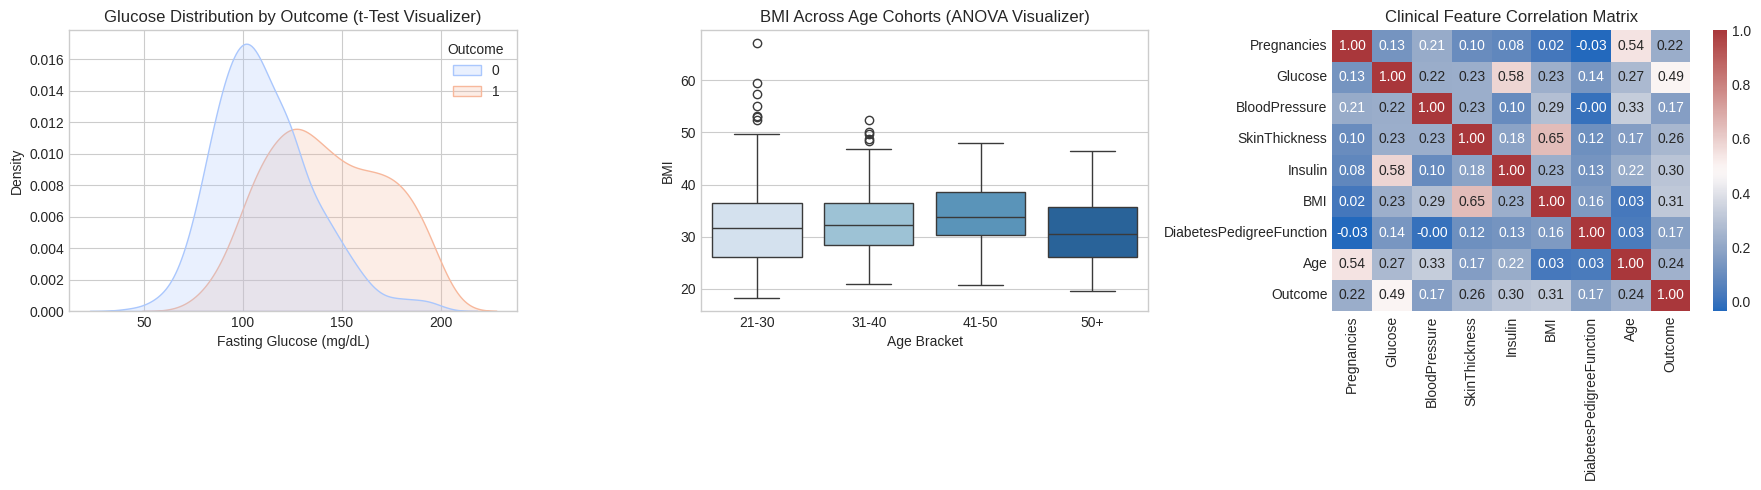

In [17]:
# SECTION 5: EXPLORATORY DATA ANALYSIS (VISUALIZATION)

# 5.1 Multi-Panel Clinical Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Fasting Glucose Distribution by Outcome
sns.kdeplot(
    data=df_clean, x='Glucose', hue='Outcome',
    common_norm=False, fill=True, palette='coolwarm', ax=axes[0]
)
axes[0].set_title("Glucose Distribution by Outcome (t-Test Visualizer)")
axes[0].set_xlabel("Fasting Glucose (mg/dL)")

# Panel 2: BMI Distribution Across Age Cohorts
sns.boxplot(
    data=df_clean, x='Age_Group', y='BMI',
    palette='Blues', ax=axes[1]
)
axes[1].set_title("BMI Across Age Cohorts (ANOVA Visualizer)")
axes[1].set_xlabel("Age Bracket")

# Panel 3: Correlation Matrix of Physiological Variables
numeric_cols = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]
corr_matrix = df_clean[numeric_cols].corr()

sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap='vlag',
    cbar=True, ax=axes[2]
)
axes[2].set_title("Clinical Feature Correlation Matrix")

plt.tight_layout()
plt.show()


In [18]:
# SECTION 6: DATA SPLITTING, IMPUTATION & SCALING

# 6.1 Train-Test Stratified Split (Leakage Prevention Protocol)
# Separate primary features from targets and synthetic testing variables
features = df_clean.drop(columns=['Outcome', 'BMI_Category', 'Age_Group', 'High_BP', 'Elevated_Fasting_Glucose'])
target = df_clean['Outcome']

# Stratify on target to retain class imbalance proportions across train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("\n--- SECTION 6: DATA SPLITTING & PREPROCESSING ---")
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

# 6.2 Multivariate Missing Data Imputation (KNN Imputer)
# Distance-weighted nearest neighbors estimate physiological values without data leakage
imputer = KNNImputer(n_neighbors=5, weights='distance')

# Fit strictly on train set; transform both train and test sets
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=features.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=features.columns, index=X_test.index)

print(f"Remaining NaNs in Train Set: {X_train_imp.isnull().sum().sum()}")
print(f"Remaining NaNs in Test Set:  {X_test_imp.isnull().sum().sum()}")

# 6.3 Feature Standardization (Z-Score Normalization)
scaler = StandardScaler()

# Fit strictly on train set; transform both train and test sets
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=features.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=features.columns)



--- SECTION 6: DATA SPLITTING & PREPROCESSING ---
X_train Shape: (614, 8) | X_test Shape: (154, 8)
Remaining NaNs in Train Set: 0
Remaining NaNs in Test Set:  0


In [19]:
# SECTION 7: FEATURE SELECTION & MODEL-READY TENSOR EXPORT

# 7.1 Statistical Feature Ranking (ANOVA F-Score Filtering)

# Extract top 5 features with strongest statistical variance separation
k_best = 5
selector = SelectKBest(score_func=f_classif, k=k_best)

X_train_selected = selector.fit_transform(X_train_scaled_df, y_train)
X_test_selected = selector.transform(X_test_scaled_df)

feature_ranking = pd.DataFrame({
    'Clinical_Feature': features.columns,
    'F_Score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values(by='F_Score', ascending=False)

print("\n--- SECTION 7: FEATURE IMPORTANCE RANKING (ANOVA F-TEST) ---")
print(feature_ranking.to_string(index=False))

selected_features = features.columns[selector.get_support()].tolist()
print(f"\nSelected Top {k_best} Features: {selected_features}")

# 7.2 Final Tensor Verification (Model-Ready Output)
print("\n--- FINAL TENSOR DIMENSIONS ---")
print(f"X_train array shape: {X_train_selected.shape} | dtype: {X_train_selected.dtype}")
print(f"X_test array shape:  {X_test_selected.shape}  | dtype: {X_test_selected.dtype}")
print(f"y_train vector shape: {y_train.shape}         | dtype: {y_train.dtype}")
print(f"y_test vector shape:  {y_test.shape}          | dtype: {y_test.dtype}")


--- SECTION 7: FEATURE IMPORTANCE RANKING (ANOVA F-TEST) ---
        Clinical_Feature    F_Score      p_value
                 Glucose 220.958050 6.758704e-43
                 Insulin  97.831593 1.685828e-21
                     BMI  74.349157 5.604218e-17
           SkinThickness  60.883692 2.627604e-14
                     Age  37.629617 1.535755e-09
             Pregnancies  27.722942 1.940682e-07
           BloodPressure  22.549239 2.553647e-06
DiabetesPedigreeFunction  17.194683 3.850392e-05

Selected Top 5 Features: ['Glucose', 'SkinThickness', 'Insulin', 'BMI', 'Age']

--- FINAL TENSOR DIMENSIONS ---
X_train array shape: (614, 5) | dtype: float64
X_test array shape:  (154, 5)  | dtype: float64
y_train vector shape: (614,)         | dtype: int64
y_test vector shape:  (154,)          | dtype: int64


**Part B: Textual Data (MTSamples Clinical Notes)**

In [23]:
# SECTION 1: SETUP, DEPENDENCIES & DATA INGESTION

# 1.1 Import Core NLP, Regex, and Deep Learning Libraries
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import AutoTokenizer

# Optional SpaCy import
try:
    import spacy
    nlp = spacy.load("en_core_web_sm")
    SPACY_AVAILABLE = True
except Exception:
    SPACY_AVAILABLE = False
    print("Notice: SpaCy model 'en_core_web_sm' not found.")

# 1.2 Ingest Raw MTSamples Dataset
url = "https://raw.githubusercontent.com/jbesomi/texthero/master/dataset/mtsamples.csv"
try:
    # Using latin1 encoding to bypass UTF-8 decoding errors common in medical text datasets
    df_raw = pd.read_csv(url, encoding='latin1')
except Exception as e:
    print(f"URL Load failed ({e}), attempting local Excel load...")
    # The local file has an .xlsx extension, so we must use read_excel
    dataset_path = 'mtsamples.csv.xlsx'
    df_raw = pd.read_excel(dataset_path)

print("--- SECTION 1: DATA INGESTION ---")
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Clean empty notes and drop unnamed index artifact column if present
df_notes = df_raw.dropna(subset=['transcription']).copy()
if 'Unnamed: 0' in df_notes.columns:
    df_notes.drop(columns=['Unnamed: 0'], inplace=True)

print(f"Active clinical notes after dropping empty entries: {len(df_notes)}")

URL Load failed (HTTP Error 404: Not Found), attempting local Excel load...
--- SECTION 1: DATA INGESTION ---
Dataset Shape: 4999 rows, 6 columns
Active clinical notes after dropping empty entries: 4966


In [39]:
# SECTION 2: HIPAA DE-IDENTIFICATION & PHI REMOVAL

# 2.1 Define Clinical Regex Patterns for Safe Harbor PHI Removal
# Patterns target: Dates, Phone numbers, SSN/MRN IDs, Ages >= 90 (HIPAA rule), Doctor/Hospital mentions
phi_patterns = {
    # Dates: MM/DD/YYYY, MM-DD-YYYY, YYYY/MM/DD, or Month DD, YYYY
    'DATE': re.compile(
        r'\b(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\d{4}[/-]\d{1,2}[/-]\d{1,2}|'
        r'(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\.?\s+\d{1,2},?\s+\d{2,4})\b',
        re.IGNORECASE
    ),
    # Phone numbers: (XXX) XXX-XXXX, XXX-XXX-XXXX
    'PHONE': re.compile(r'\b(?:\+?\d{1,2}\s*)?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}\b'),
    # Medical Record Numbers (MRN) or Account/SSN IDs
    'ID_NUM': re.compile(r'\b(?:MRN|ID|SSN|ACCT)[\s#:]*([A-Z0-9-]{5,12})\b', re.IGNORECASE),
    # Doctor / Clinician Names (e.g., "Dr. Smith", "Attending: Dr. John")
    'DOCTOR': re.compile(r'\b(?:Dr\.|Doctor)\s+([A-Z][a-z]+(?:\s+[A-Z][a-z]+)?)\b'),
    # Hospital / Clinic Facilities
    'HOSPITAL': re.compile(r'\b[A-Z][a-zA-Z\s]+(?:Hospital|Clinic|Medical Center|Infirmary)\b'),
    # Ages over 89 (HIPAA requires aggregating all ages 90+ into an indicator category)
    'AGE_90_PLUS': re.compile(r'\b(?:9\d|1\d{2})[- ]?(?:years?[- ]?old|yo|y/o)\b', re.IGNORECASE)
}

# 2.2 Execute PHI Masking Pipeline
def redact_phi(text: str) -> str:
    """Masks direct clinical identifiers with standardized tokens."""
    if not isinstance(text, str):
        return ""

    # 1. Regex Replacements
    text = phi_patterns['DATE'].sub('[DATE]', text)
    text = phi_patterns['PHONE'].sub('[PHONE]', text)
    text = phi_patterns['ID_NUM'].sub('[ID_NUM]', text)
    text = phi_patterns['DOCTOR'].sub('Dr. [NAME]', text)
    text = phi_patterns['HOSPITAL'].sub('[FACILITY]', text)
    text = phi_patterns['AGE_90_PLUS'].sub('[AGE_90+]', text)

    # 2. SpaCy NER Redaction (Optional pass for personal names & locations)
    if SPACY_AVAILABLE:
        doc = nlp(text)
        for ent in doc.ents:
            if ent.label_ in ['PERSON']:
                text = text.replace(ent.text, '[NAME]')
            elif ent.label_ in ['GPE', 'LOC']:
                text = text.replace(ent.text, '[LOCATION]')

    return text

print("\n--- SECTION 2: PHI DE-IDENTIFICATION TESTING ---")
sample_raw_note = (
    "Patient Jane Doe (MRN #9283471) presented to City General Hospital on 04/15/2021. "
    "Contact number: 555-234-5678. The 92-year-old female was seen by Dr. Emily Stone."
)
print("Before De-identification:\n", sample_raw_note)
print("\nAfter De-identification:\n", redact_phi(sample_raw_note))

# Apply masking across the entire corpus
df_notes['clean_transcription'] = df_notes['transcription'].apply(redact_phi)


--- SECTION 2: PHI DE-IDENTIFICATION TESTING ---
Before De-identification:
 Patient Jane Doe (MRN #9283471) presented to City General Hospital on 04/15/2021. Contact number: 555-234-5678. The 92-year-old female was seen by Dr. Emily Stone.

After De-identification:
 Patient [NAME] ([ID_NUM]) presented to [FACILITY] on [DATE]. Contact number: [PHONE]. The [AGE_90+] female was seen by Dr. [NAME].


In [40]:
# SECTION 3: CLINICAL TEXT NORMALIZATION & STANDARDIZATION

# 3.1 Medical Abbreviations Expansion
# Expanding domain-specific shorthand prevents subword tokenizer fragmentation
abbreviation_map = {
    r'\bb\.?i\.?d\.?\b': 'twice daily',
    r'\bt\.?i\.?d\.?\b': 'three times daily',
    r'\bq\.?i\.?d\.?\b': 'four times daily',
    r'\bq\.?d\.?\b': 'once daily',
    r'\bp\.?r\.?n\.?\b': 'as needed',
    r'\bh\.?o\.?\b': 'history of',
    r'\bs\.?o\.?b\.?\b': 'shortness of breath',
    r'\bd\.?x\.?\b': 'diagnosis',
    r'\br\.?x\.?\b': 'prescription',
    r'\by\.?o\.?\b': 'year old',
    r'\bw\.?o\.?\b': 'without'
}

def expand_abbreviations(text: str) -> str:
    for pattern, replacement in abbreviation_map.items():
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)
    return text

# 3.2 Clinical Text Sanitization
def sanitize_clinical_text(text: str) -> str:
    # Expand abbreviations
    text = expand_abbreviations(text)
    # Strip carriage returns and non-standard whitespace artifacts
    text = re.sub(r'[\r\n\t]+', ' ', text)
    # Strip multiple consecutive spaces
    text = re.sub(r'\s{2,}', ' ', text)
    # Lowercase text while preserving HIPAA masked placeholder tokens
    # E.g., [DATE] -> [date]
    text = text.strip().lower()
    return text

df_notes['clean_transcription'] = df_notes['clean_transcription'].apply(sanitize_clinical_text)
print("\n--- SECTION 3: NORMALIZED SAMPLE ---")
print(df_notes['clean_transcription'].iloc[0][:300], "...")


--- SECTION 3: NORMALIZED SAMPLE ---
subjective:, this 23-year-old white female presents with complaint of allergies. she used to have allergies when she lived in [location] but she thinks they are worse here. in the past, she has tried [name], and zyrtec. both worked for short time but then seemed to lose effectiveness. she has used a ...



--- SECTION 4: CLINICAL NOTE STATISTICS ---
                  mean          std   min     50%      max
word_count   463.98530   314.609023   1.0   398.5   2918.0
char_count  3021.78534  1984.694507  11.0  2638.0  18801.0


/tmp/ipykernel_815/185281958.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_specialties.values, y=top_specialties.index, ax=axes[0], palette='crest')


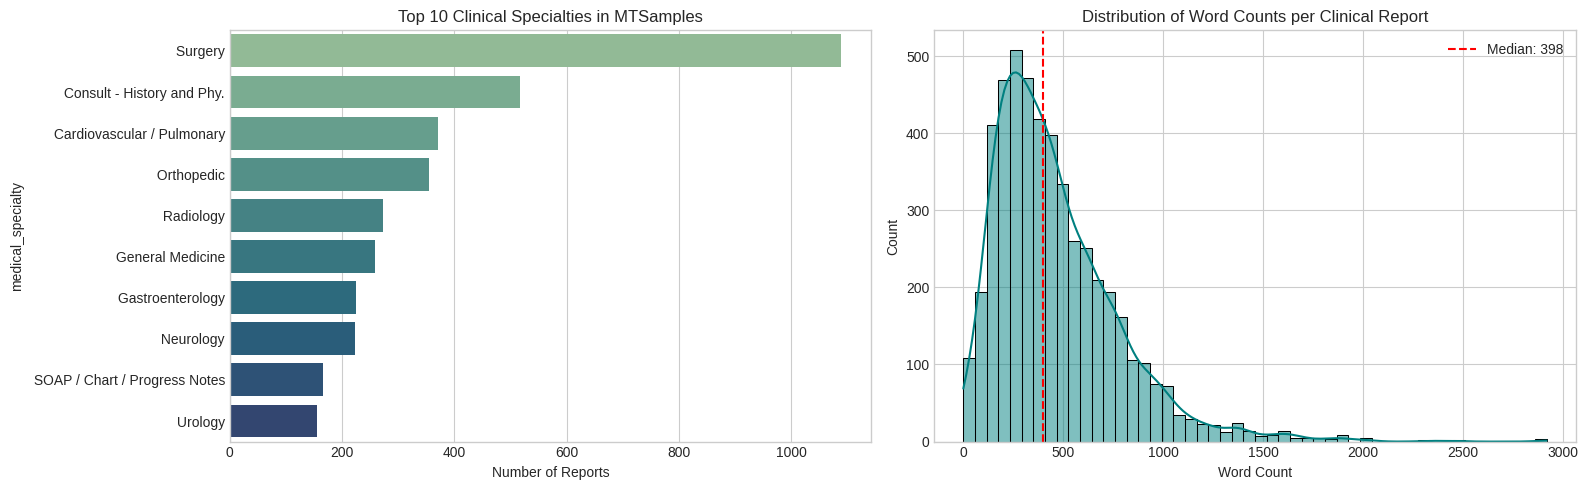

In [41]:
# SECTION 4: EXPLORATORY DATA ANALYSIS (EDA)

# 4.1 Compute Note Length & Distribution Statistics
df_notes['word_count'] = df_notes['clean_transcription'].apply(lambda x: len(x.split()))
df_notes['char_count'] = df_notes['clean_transcription'].apply(len)

print("\n--- SECTION 4: CLINICAL NOTE STATISTICS ---")
print(df_notes[['word_count', 'char_count']].describe().T[['mean', 'std', 'min', '50%', 'max']])

# 4.2 Visualizing Top Medical Specialties & Token Distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Top 10 Medical Specialties
top_specialties = df_notes['medical_specialty'].value_counts().head(10)
sns.barplot(x=top_specialties.values, y=top_specialties.index, ax=axes[0], palette='crest')
axes[0].set_title("Top 10 Clinical Specialties in MTSamples")
axes[0].set_xlabel("Number of Reports")

# Plot 2: Distribution of Clinical Word Lengths
sns.histplot(df_notes['word_count'], bins=50, kde=True, ax=axes[1], color='teal')
axes[1].axvline(df_notes['word_count'].median(), color='red', linestyle='--', label=f"Median: {int(df_notes['word_count'].median())}")
axes[1].set_title("Distribution of Word Counts per Clinical Report")
axes[1].set_xlabel("Word Count")
axes[1].legend()

plt.tight_layout()
plt.show()

In [42]:
# SECTION 5: CLINICAL TOKENIZATION & TENSOR PREPARATION

# 5.1 Initialize Pretrained Clinical/Biomedical Tokenizer
# Using 'emilyalsentzer/Bio_ClinicalBERT' (specialized on MIMIC-III EHR notes)
# Fallback to standard 'bert-base-uncased' if offline or download fails
model_identifier = "emilyalsentzer/Bio_ClinicalBERT"

try:
    print(f"\nLoading Clinical Tokenizer: {model_identifier}...")
    tokenizer = AutoTokenizer.from_pretrained(model_identifier)
except Exception:
    print("Falling back to standard 'bert-base-uncased' tokenizer...")
    tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# 5.2 Register Custom Special Tokens for PHI Identifiers
# Prevents the tokenizer from splitting [date], [name], etc. into subword fragments
phi_special_tokens = {
    "additional_special_tokens": [
        "[date]", "[phone]", "[id_num]", "[name]", "[facility]", "[age_90+]", "[location]"
    ]
}
num_added_tokens = tokenizer.add_special_tokens(phi_special_tokens)
print(f"Added {num_added_tokens} custom PHI tokens to tokenizer vocabulary.")

# 5.3 Batch Encoding into Model-Ready PyTorch Tensors
# Transformer context limit is typically 512 tokens
MAX_SEQ_LENGTH = 256
sample_batch_size = 500  # Tokenize a representative subset or full dataset

clinical_corpus = df_notes['clean_transcription'].iloc[:sample_batch_size].tolist()

encoded_batch = tokenizer(
    clinical_corpus,
    padding='max_length',       # Pad sequences with [PAD] (ID=0)
    truncation=True,            # Truncate sequences longer than max_length
    max_length=MAX_SEQ_LENGTH,
    return_attention_mask=True, # 1 for real tokens, 0 for padded tokens
    return_tensors="pt"         # Output PyTorch tensors
)

input_ids = encoded_batch['input_ids']
attention_mask = encoded_batch['attention_mask']

# 5.4 Verify Model-Ready Tensors
print("\n" + "="*60)
print("     FINAL MODEL-READY TEXTUAL TENSORS")
print("="*60)
print(f"Input IDs Tensor Shape:       {input_ids.shape} (Batch_Size, Seq_Len)")
print(f"Attention Mask Tensor Shape:  {attention_mask.shape}")
print(f"Data Type:                    {input_ids.dtype}")
print(f"\nSample Tokenized IDs (First Sequence):\n{input_ids[0][:25]}...")
print(f"\nDecoded Back to Text:\n{tokenizer.decode(input_ids[0][:25])}")


Loading Clinical Tokenizer: emilyalsentzer/Bio_ClinicalBERT...


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Added 7 custom PHI tokens to tokenizer vocabulary.

     FINAL MODEL-READY TEXTUAL TENSORS
Input IDs Tensor Shape:       torch.Size([500, 256]) (Batch_Size, Seq_Len)
Attention Mask Tensor Shape:  torch.Size([500, 256])
Data Type:                    torch.int64

Sample Tokenized IDs (First Sequence):
tensor([  101, 23481,   131,   117,  1142,  1695,   118,  1214,   118,  1385,
         1653,  2130,  8218,  1114, 12522,  1104,  1155,  1200, 19310,   119,
         1131,  1215,  1106,  1138,  1155])...

Decoded Back to Text:
[CLS] subjective :, this 23 - year - old white female presents with complaint of allergies. she used to have all


**Part C: Image Data (Chest X-Rays for Pneumonia)**

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [7]:
# SECTION 1: SETUP, KAGGLEHUB PATH RESOLUTION & AUDIT

# 1.1 Import Core Scientific, Computer Vision, and Deep Learning Libraries
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Set reproducible seeds
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

# 1.2 Resolve Kagglehub Dataset Directory
# If you ran the kagglehub snippet in a prior cell, use 'path'.
# Otherwise, we ensure it's defined:
try:
    BASE_DIR = path
except NameError:
    import kagglehub
    BASE_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print(f"Kagglehub Root Path: {BASE_DIR}")

# Resolve the nested 'chest_xray' subdirectory standard in this dataset
nested_candidate = os.path.join(BASE_DIR, "chest_xray")
if os.path.exists(nested_candidate) and os.path.exists(os.path.join(nested_candidate, "train")):
    DATA_DIR = nested_candidate
elif os.path.exists(os.path.join(BASE_DIR, "train")):
    DATA_DIR = BASE_DIR
else:
    # Handles chest_xray/chest_xray double-nesting
    deep_nested = os.path.join(nested_candidate, "chest_xray")
    DATA_DIR = deep_nested if os.path.exists(deep_nested) else BASE_DIR

print(f"Resolved Data Directory: {DATA_DIR}")
print("Subfolders found:", os.listdir(DATA_DIR))

# 1.3 Dataset Verification & Class Count
splits = ['train', 'val', 'test']
classes = ['NORMAL', 'PNEUMONIA']
dataset_summary = {}

for s in splits:
    dataset_summary[s] = {}
    for c in classes:
        target_dir = os.path.join(DATA_DIR, s, c)
        count = len(glob.glob(os.path.join(target_dir, "*.*")))
        dataset_summary[s][c] = count

print("\n--- SECTION 1: SPLIT INVENTORY ---")
for s in splits:
    print(f"Split [{s:>5}]: NORMAL = {dataset_summary[s]['NORMAL']:>4} | PNEUMONIA = {dataset_summary[s]['PNEUMONIA']:>4}")

Using compute device: cuda
Kagglehub Root Path: /kaggle/input/chest-xray-pneumonia
Resolved Data Directory: /kaggle/input/chest-xray-pneumonia/chest_xray
Subfolders found: ['chest_xray', '__MACOSX', 'val', 'test', 'train']

--- SECTION 1: SPLIT INVENTORY ---
Split [train]: NORMAL = 1341 | PNEUMONIA = 3875
Split [  val]: NORMAL =    8 | PNEUMONIA =    8
Split [ test]: NORMAL =  234 | PNEUMONIA =  390


In [27]:
# SECTION 2: METADATA & ARTIFACT SANITIZATION

# 2.1 Anonymization & EXIF Stripping
def sanitize_medical_image(file_path: str) -> Image.Image:
    """
    Strips camera metadata, institution headers, and EXIF tags from radiographs
    by extracting the raw pixel buffer into an in-memory, decoupled PIL Image.
    """
    with Image.open(file_path) as raw_img:
        # Convert to standard RGB (standardizes both 1-channel grayscale and 3-channel saves)
        rgb_img = raw_img.convert('RGB')
        pixel_data = list(rgb_img.getdata())
        clean_img = Image.new(rgb_img.mode, rgb_img.size)
        clean_img.putdata(pixel_data)
        return clean_img

# Verify sanitization on an arbitrary sample
sample_train_file = glob.glob(os.path.join(DATA_DIR, 'train', 'NORMAL', '*.*'))[0]
test_cleaned_img = sanitize_medical_image(sample_train_file)
print("\n--- SECTION 2: METADATA SANITIZATION ---")
print(f"Sample Image Size:     {test_cleaned_img.size}")
print(f"Color Mode:            {test_cleaned_img.mode}")
print(f"Remaining EXIF Header: {getattr(test_cleaned_img, '_getexif', lambda: None)()}")


--- SECTION 2: METADATA SANITIZATION ---
Sample Image Size:     (1336, 1128)
Color Mode:            RGB
Remaining EXIF Header: None


In [8]:
# SECTION 3: DOMAIN-SPECIFIC MEDICAL AUGMENTATION PIPELINE

# 3.1 Define Biologically Plausible Transformations
# In chest radiography:
# - Strictly AVOID vertical flips (violates thoracic anatomy; heart is on the left).
# - Allow subtle horizontal flips, gentle rotations (+/- 10 deg), and mild contrast jitter.
IMAGE_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

print("\n--- SECTION 3: TRANSFORM PIPELINE READY ---")
print(f"Input Resolution: {IMAGE_SIZE}x{IMAGE_SIZE} | Normalization: ImageNet Channel Stats")


--- SECTION 3: TRANSFORM PIPELINE READY ---
Input Resolution: 224x224 | Normalization: ImageNet Channel Stats


In [9]:
# SECTION 4: PYTORCH DATASET & DATALOADERS

# 4.1 Custom Dataset with In-Flight De-identification
class KaggleChestXRayDataset(Dataset):
    def __init__(self, data_root, split='train', transform=None):
        self.split_dir = os.path.join(data_root, split)
        self.transform = transform
        self.samples = []

        # 0: NORMAL, 1: PNEUMONIA
        class_mapping = {'NORMAL': 0, 'PNEUMONIA': 1}

        for class_name, label_idx in class_mapping.items():
            folder = os.path.join(self.split_dir, class_name)
            for f in glob.glob(os.path.join(folder, "*.*")):
                if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.samples.append((f, label_idx))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]
        # In-flight de-identification / EXIF stripping
        img = sanitize_medical_image(file_path)

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)

# 4.2 Initialize DataLoaders
BATCH_SIZE = 32

train_dataset = KaggleChestXRayDataset(DATA_DIR, split='train', transform=train_transforms)
val_dataset   = KaggleChestXRayDataset(DATA_DIR, split='val', transform=eval_transforms)
test_dataset  = KaggleChestXRayDataset(DATA_DIR, split='test', transform=eval_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("\n--- SECTION 4: DATALOADERS CREATED ---")
print(f"Train Dataset: {len(train_dataset)} images | {len(train_loader)} batches")
print(f"Val Dataset:   {len(val_dataset)} images   | {len(val_loader)} batches")
print(f"Test Dataset:  {len(test_dataset)} images  | {len(test_loader)} batches")


--- SECTION 4: DATALOADERS CREATED ---
Train Dataset: 5216 images | 163 batches
Val Dataset:   16 images   | 1 batches
Test Dataset:  624 images  | 20 batches


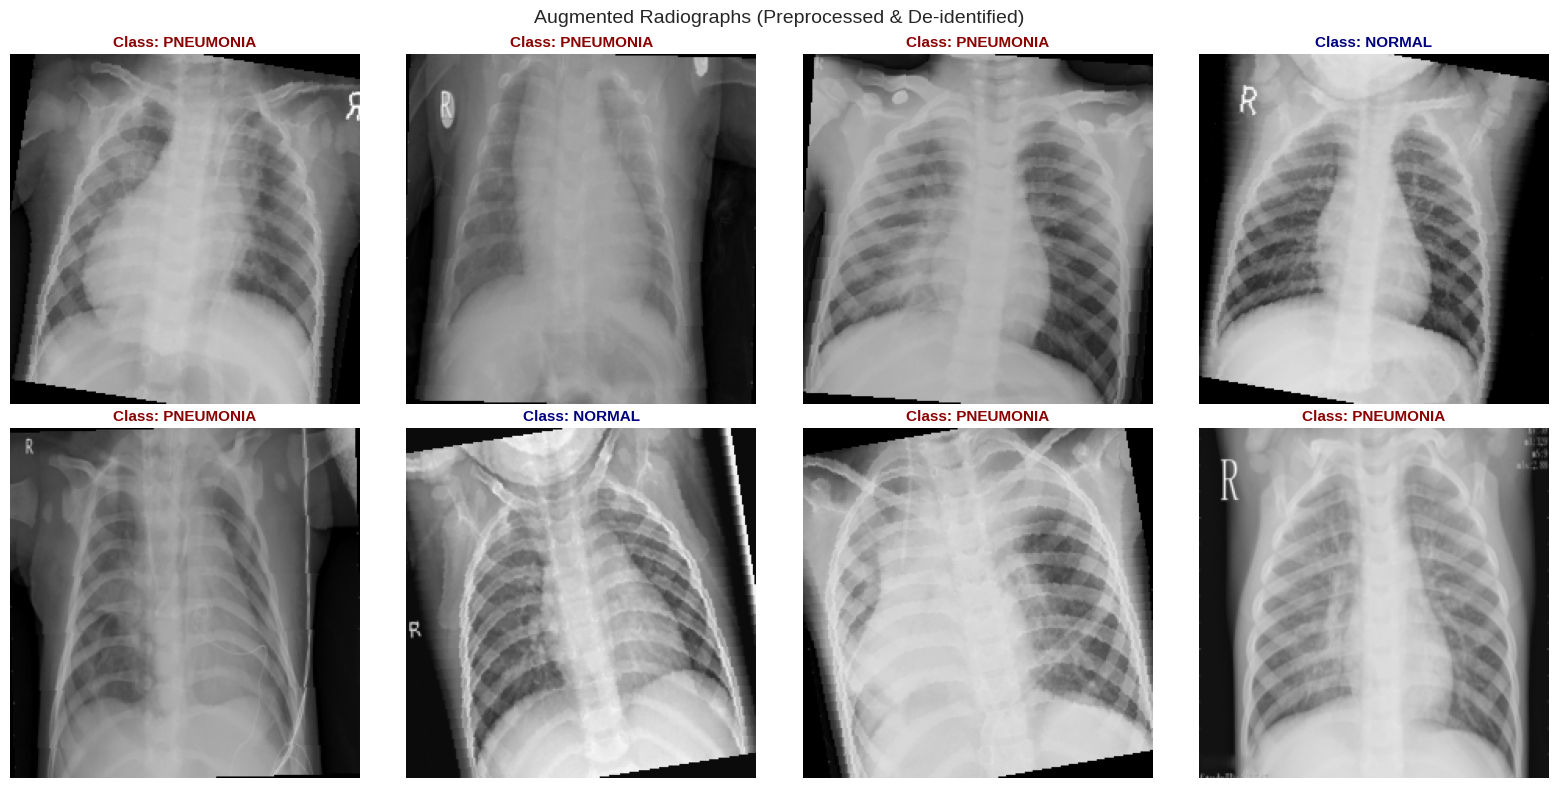

In [11]:
# SECTION 5: EXPLORATORY DATA ANALYSIS & VISUALIZATION

# 5.1 Display Batch with Denormalization

from PIL import Image

def sanitize_medical_image(file_path: str) -> Image.Image:
    """
    Strips camera metadata, institution headers, and EXIF tags from radiographs
    by extracting the raw pixel buffer into an in-memory, decoupled PIL Image.
    """
    with Image.open(file_path) as raw_img:
        rgb_img = raw_img.convert('RGB')
        pixel_data = list(rgb_img.getdata())
        clean_img = Image.new(rgb_img.mode, rgb_img.size)
        clean_img.putdata(pixel_data)
        return clean_img

def denormalize(tensor):
    """Reverses ImageNet normalization back to [0, 1] RGB for plotting."""
    t = tensor.clone()
    for channel, mean, std in zip(t, NORM_MEAN, NORM_STD):
        channel.mul_(std).add_(mean)
    return torch.clamp(t, 0, 1)

# Note: This requires train_loader to be defined in the previous cell
images_batch, labels_batch = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(8):
    display_img = denormalize(images_batch[i]).permute(1, 2, 0).numpy()
    label_text = "PNEUMONIA" if labels_batch[i].item() == 1 else "NORMAL"
    title_color = "darkred" if label_text == "PNEUMONIA" else "navy"

    axes[i].imshow(display_img)
    axes[i].set_title(f"Class: {label_text}", fontsize=11, fontweight='bold', color=title_color)
    axes[i].axis('off')

plt.suptitle("Augmented Radiographs (Preprocessed & De-identified)", fontsize=14)
plt.tight_layout()
plt.show()

In [28]:
# SECTION 6: HEALTHCARE CLASS IMBALANCE MITIGATION

# 6.1 Compute Loss Penalties via Inverse Frequency
# Pneumonia images outnumber Normal images significantly in the training split
n_norm = dataset_summary['train']['NORMAL']
n_pneu = dataset_summary['train']['PNEUMONIA']
n_total = n_norm + n_pneu

w_norm = n_total / (2.0 * n_norm)
w_pneu = n_total / (2.0 * n_pneu)
class_weights = torch.tensor([w_norm, w_pneu], dtype=torch.float).to(device)

print("\n--- SECTION 6: INVERSE CLASS WEIGHTS ---")
print(f"Normal Class Weight:    {w_norm:.4f}")
print(f"Pneumonia Class Weight: {w_pneu:.4f}")

# Plug directly into PyTorch's loss function
criterion = nn.CrossEntropyLoss(weight=class_weights)
print("Configured weighted CrossEntropyLoss ready for model training.")


--- SECTION 6: INVERSE CLASS WEIGHTS ---
Normal Class Weight:    1.9448
Pneumonia Class Weight: 0.6730
Configured weighted CrossEntropyLoss ready for model training.


In [29]:
# SECTION 7: FINAL MODEL-READY TENSOR VERIFICATION

# 7.1 Verify Tensor Shapes and Range
print("\n" + "="*60)
print("     FINAL MODEL-READY TENSORS (PART C)")
print("="*60)
print(f"Batch Tensor Shape:  {images_batch.shape} -> (Batch, Channels, Height, Width)")
print(f"Labels Tensor Shape: {labels_batch.shape}")
print(f"Tensor Dtype:        {images_batch.dtype}")
print(f"Standardized Range:  [{images_batch.min().item():.3f}, {images_batch.max().item():.3f}]")


     FINAL MODEL-READY TENSORS (PART C)
Batch Tensor Shape:  torch.Size([32, 3, 224, 224]) -> (Batch, Channels, Height, Width)
Labels Tensor Shape: torch.Size([32])
Tensor Dtype:        torch.float32
Standardized Range:  [-2.118, 2.640]


**Part D: Signal Data (MIT-BIH Arrhythmia Database - ECG)**

In [30]:
!pip install wfdb

# SECTION 0: UNZIP & DISCOVER MIT-BIH PHYSIONET RECORD

import os
import glob
import zipfile
import wfdb

# 0.1 Find and Extract the Zip Archive
zip_candidates = glob.glob("*.zip")
target_zip = None

for z in zip_candidates:
    if any(k in z.lower() for k in ['mit', 'arrhythmia', 'physio', '1.0.0']):
        # Verify if it is actually a valid zip file
        if zipfile.is_zipfile(z):
            target_zip = z
            break

EXTRACT_DIR = "mitdb"
os.makedirs(EXTRACT_DIR, exist_ok=True)

if target_zip:
    print(f"Target zip archive found: {target_zip}")
    try:
        print(f"Extracting '{target_zip}' into ./{EXTRACT_DIR}/ ...")
        with zipfile.ZipFile(target_zip, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_DIR)
        print("Extraction complete!")
    except zipfile.BadZipFile:
        print(f"Error: '{target_zip}' is corrupted. Falling back to wfdb download...")
        target_zip = None

# 0.2 Fallback: Download via wfdb if no zip or zip is invalid
if not target_zip:
    print("Downloading MIT-BIH record '100' directly from PhysioNet...")
    wfdb.dl_database('mitdb', dl_dir=EXTRACT_DIR, records=['100'], keep_subdirs=False)

# 0.3 Locate Valid WFDB Record Prefix
hea_matches = glob.glob(f"{EXTRACT_DIR}/**/*.hea", recursive=True)
if not hea_matches:
    hea_matches = glob.glob("**/*.hea", recursive=True)

if hea_matches:
    first_hea = hea_matches[0]
    record_prefix = os.path.splitext(first_hea)[0]
    print(f"\nDiscovered valid WFDB record: '{record_prefix}'")
else:
    record_prefix = os.path.join(EXTRACT_DIR, '100')
    print(f"\nWarning: Defaulting to: '{record_prefix}'")

# 0.4 Test Load
try:
    test_rec = wfdb.rdrecord(record_prefix, sampto=1000)
    print("Verification Successful!")
    print(f"Record Name: {test_rec.record_name}")
    print(f"Sampling Frequency: {test_rec.fs} Hz")
    print(f"Number of Channels: {test_rec.n_sig}")
    print(f"Signal Leads: {test_rec.sig_name}")
except Exception as e:
    print(f"Verification Failed: {e}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.4 MB/s eta 0:00:00
Target zip archive found: mit-bih-arrhythmia-database-1.0.0 (1).zip
Extracting 'mit-bih-arrhythmia-database-1.0.0 (1).zip' into ./mitdb/ ...
Extraction complete!

Discovered valid WFDB record: 'mitdb/mit-bih-arrhythmia-database-1.0.0/208'
Verification Successful!
Record Name: 208
Sampling Frequency: 360 Hz
Number of Channels: 2
Signal Leads: ['MLII', 'V1']


In [31]:
# Pass the discovered path to rdrecord and rdann
record = wfdb.rdrecord(record_prefix, sampto=10000)
annotation = wfdb.rdann(record_prefix, 'atr', sampto=10000)

In [32]:
pip install wfdb scipy torch matplotlib numpy

In [33]:
# SECTION 1: SETUP, DEPENDENCIES & RAW WFDB INGESTION

# 1.1 Import Signal Processing, WFDB, and Deep Learning Libraries
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

import wfdb  # Official PhysioNet Waveform Database library
import torch
from torch.utils.data import TensorDataset, DataLoader

# 1.2 Locate and Load Native PhysioNet WFDB Record
# Look for downloaded header files (e.g., '100.hea') in the current directory or subfolders
hea_files = glob.glob("**/*.hea", recursive=True)

if hea_files:
    # Strip extension to get the record path prefix (e.g., '100' from '100.hea')
    record_prefix = os.path.splitext(hea_files[0])[0]
    print(f"Found WFDB record: '{record_prefix}'")
else:
    # If unzipped in a specific folder or default naming
    record_prefix = '100'
    print(f"No .hea file auto-discovered. Defaulting to record: '{record_prefix}'")

# Load signal data and physician beat annotations
try:
    # Read the first 10,000 samples (first ~28 seconds at 360 Hz)
    record = wfdb.rdrecord(record_prefix, sampto=10000)
    annotation = wfdb.rdann(record_prefix, 'atr', sampto=10000)

    fs = record.fs                          # Sampling frequency: 360 Hz
    raw_signal = record.p_signal[:, 0]      # Channel 0: Modified Lead II (MLII)
    lead_name = record.sig_name[0]
    ann_sample_indices = annotation.sample  # Expert-annotated R-peak sample locations
    ann_symbols = annotation.symbol         # Beat classifications (e.g., 'N', 'V', 'A')

    print(f"\n--- SECTION 1: WFDB METADATA ---")
    print(f"Sampling Frequency (fs): {fs} Hz")
    print(f"Lead Name:               {lead_name}")
    print(f"Signal Samples Loaded:   {len(raw_signal)}")
    print(f"Total Annotated Beats:   {len(ann_sample_indices)}")

except Exception as e:
    print(f"Error loading record: {e}")
    print("Ensure .dat, .hea, and .atr files for the record are in the same folder.")
    raise SystemExit

Found WFDB record: 'mitdb/mit-bih-arrhythmia-database-1.0.0/208'

--- SECTION 1: WFDB METADATA ---
Sampling Frequency (fs): 360 Hz
Lead Name:               MLII
Signal Samples Loaded:   10000
Total Annotated Beats:   50


In [34]:
# SECTION 2: DIGITAL NOISE REMOVAL (BANDPASS & NOTCH FILTERING)

# 2.1 Butterworth Bandpass Filter (0.5 Hz - 40.0 Hz)
# Baseline wander (respiration) occurs at 0.1 - 0.5 Hz.
# Muscle tremors (electromyographic noise) occur at frequencies above 40 Hz.
def butter_bandpass(data, lowcut=0.5, highcut=40.0, sampling_rate=360, order=3):
    nyquist = 0.5 * sampling_rate
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    # Zero-phase bidirectional digital filter to prevent phase distortion
    return signal.filtfilt(b, a, data)

# 2.2 IIR Notch Filter (60 Hz Powerline Mains Hum)
# Note: The MIT-BIH Arrhythmia Database was recorded in the US (60 Hz mains frequency)
def notch_filter(data, cutoff=60.0, sampling_rate=360, quality_factor=30.0):
    nyquist = 0.5 * sampling_rate
    freq = cutoff / nyquist
    b, a = signal.iirnotch(freq, quality_factor)
    return signal.filtfilt(b, a, data)

# Apply cascaded noise removal
bandpassed_sig = butter_bandpass(raw_signal, lowcut=0.5, highcut=40.0, sampling_rate=fs)
cleaned_signal = notch_filter(bandpassed_sig, cutoff=60.0, sampling_rate=fs)

print("\n--- SECTION 2: FILTERING COMPLETE ---")
print(f"Noise suppression applied: Bandpass (0.5 - 40 Hz) + Notch (60 Hz at Q=30)")


--- SECTION 2: FILTERING COMPLETE ---
Noise suppression applied: Bandpass (0.5 - 40 Hz) + Notch (60 Hz at Q=30)


In [35]:
# SECTION 3: R-PEAK DETECTION (PAN-TOMPKINS PRINCIPLES)

# 3.1 Derivative, Squaring & Moving Integration (Pan-Tompkins Feature Extractor)
# 1. First-order differentiator isolates steep QRS slopes
diff_signal = np.diff(cleaned_signal)

# 2. Non-linear squaring operator amplifies QRS complexes and attenuates P/T waves
squared_signal = diff_signal ** 2

# 3. Moving average window (~150 ms integration window: 0.15 * 360 = 54 samples)
integration_window = int(0.15 * fs)
integrated_signal = np.convolve(squared_signal, np.ones(integration_window) / integration_window, mode='same')

# 3.2 Dynamic Thresholding for R-Peak Localization
# Refractory period: minimum 200 ms between adjacent heartbeats (72 samples at 360 Hz)
min_distance = int(0.20 * fs)
threshold = np.mean(integrated_signal) + 1.2 * np.std(integrated_signal)

detected_peaks, _ = signal.find_peaks(
    integrated_signal,
    distance=min_distance,
    height=threshold
)

print("\n--- SECTION 3: PEAK DETECTION RESULTS ---")
print(f"Algorithm Detected Peaks: {len(detected_peaks)}")
print(f"Physician ATR Ground Truth Peaks: {len(ann_sample_indices)}")


--- SECTION 3: PEAK DETECTION RESULTS ---
Algorithm Detected Peaks: 28
Physician ATR Ground Truth Peaks: 50


In [36]:
# SECTION 4: TEMPORAL BEAT SEGMENTATION & NORMALIZATION

# 4.1 Fixed Temporal Slicing (Pre-R & Post-R Windows)
# Cardiac window at 360 Hz:
# 200 ms before R-peak (P-wave): 0.20 * 360 = 72 samples
# 400 ms after R-peak (T-wave):  0.40 * 360 = 144 samples
# Total window size: 216 samples (~600 ms)
PRE_R_SAMPLES = int(0.20 * fs)   # 72
POST_R_SAMPLES = int(0.40 * fs)  # 144
WINDOW_LEN = PRE_R_SAMPLES + POST_R_SAMPLES

# Mapping AAMI standard arrhythmia categories
# Normal (N): 0 | Supraventricular (S): 1 | Ventricular (V): 2 | Fusion (F): 3 | Unknown (Q): 4
aami_mapping = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,       # Non-ectopic
    'A': 1, 'a': 1, 'J': 1, 'S': 1,               # Supraventricular ectopic
    'V': 2, 'E': 2,                               # Ventricular ectopic
    'F': 3,                                       # Fusion
    '/': 4, 'f': 4, 'Q': 4, '?': 4                # Unknown / Paced
}

segmented_beats = []
beat_labels = []

# Slice windows using the physician ground-truth R-peaks for clean supervised extraction
for r_peak, sym in zip(ann_sample_indices, ann_symbols):
    start = r_peak - PRE_R_SAMPLES
    end = r_peak + POST_R_SAMPLES

    if start >= 0 and end <= len(cleaned_signal):
        beat = cleaned_signal[start:end]
        # Z-score standardization per heartbeat (zero mean, unit variance)
        beat_normalized = (beat - np.mean(beat)) / (np.std(beat) + 1e-8)

        segmented_beats.append(beat_normalized)
        beat_labels.append(aami_mapping.get(sym, 4))

segmented_beats = np.array(segmented_beats)
beat_labels = np.array(beat_labels)

print("\n--- SECTION 4: SEGMENTATION & EXTRACTION ---")
print(f"Segmented Heartbeats Array Shape: {segmented_beats.shape} (Beats, Timesteps)")
print(f"Extracted Labels Count:           {len(beat_labels)}")


--- SECTION 4: SEGMENTATION & EXTRACTION ---
Segmented Heartbeats Array Shape: (48, 216) (Beats, Timesteps)
Extracted Labels Count:           48


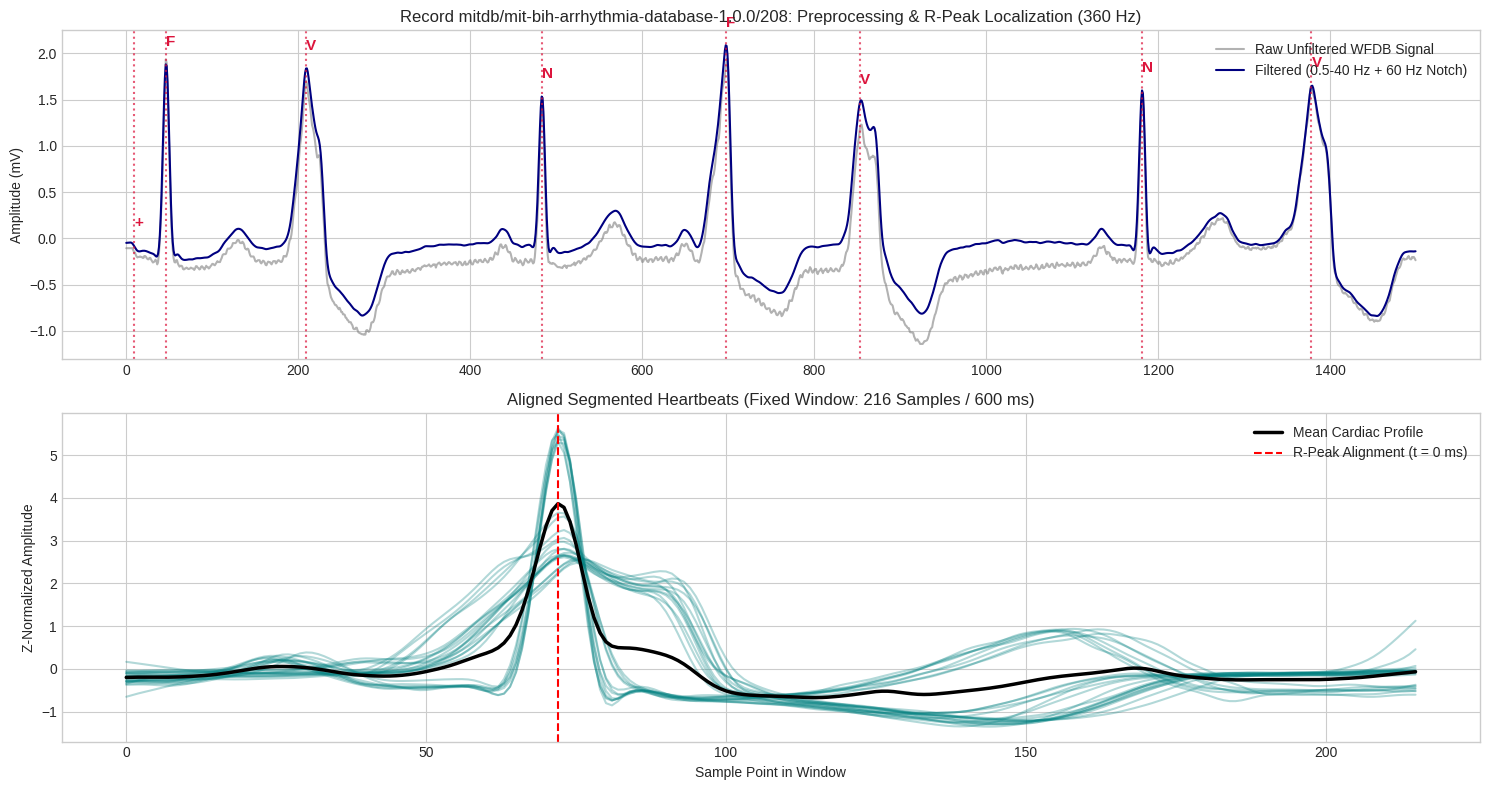

In [37]:
# SECTION 5: EXPLORATORY DATA ANALYSIS (EDA) & PLOTS

# 5.1 Artifact Removal & Beat Window Overlays
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# Panel 1: Filter Comparison over 1,500 samples (~4.1 seconds)
display_len = 1500
axes[0].plot(raw_signal[:display_len], label='Raw Unfiltered WFDB Signal', color='gray', alpha=0.6)
axes[0].plot(cleaned_signal[:display_len], label='Filtered (0.5-40 Hz + 60 Hz Notch)', color='navy', lw=1.5)

# Plot ground truth annotations on raw trace
local_anns = [(p, s) for p, s in zip(ann_sample_indices, ann_symbols) if p < display_len]
for p, s in local_anns:
    axes[0].axvline(p, color='crimson', linestyle=':', alpha=0.7)
    axes[0].text(p, cleaned_signal[p] + 0.2, s, color='crimson', fontweight='bold', fontsize=11)

axes[0].set_title(f"Record {record_prefix}: Preprocessing & R-Peak Localization (360 Hz)")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].legend(loc="upper right")

# Panel 2: Superposition of Aligned Single Cardiac Cycles
if len(segmented_beats) > 0:
    for i in range(min(25, len(segmented_beats))):
        axes[1].plot(segmented_beats[i], color='teal', alpha=0.3)

    # Plot mean beat template
    mean_beat = np.mean(segmented_beats, axis=0)
    axes[1].plot(mean_beat, color='black', lw=2.5, label='Mean Cardiac Profile')
    axes[1].axvline(PRE_R_SAMPLES, color='red', linestyle='--', label=f'R-Peak Alignment (t = 0 ms)')

axes[1].set_title(f"Aligned Segmented Heartbeats (Fixed Window: {WINDOW_LEN} Samples / 600 ms)")
axes[1].set_xlabel("Sample Point in Window")
axes[1].set_ylabel("Z-Normalized Amplitude")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [38]:
# SECTION 6: MODEL-READY 1D CONVOLUTIONAL TENSORS

# 6.1 Convert to Model-Ready PyTorch Tensor Batches
# Deep learning architectures (1D CNNs, ResNets) expect shape: (Batch, Channels, Length)
X_tensor = torch.tensor(segmented_beats, dtype=torch.float32).unsqueeze(1)
y_tensor = torch.tensor(beat_labels, dtype=torch.long)

batch_size = 16
ecg_dataset = TensorDataset(X_tensor, y_tensor)
ecg_loader = DataLoader(ecg_dataset, batch_size=batch_size, shuffle=True)

sample_batch_x, sample_batch_y = next(iter(ecg_loader))

print("\n" + "="*60)
print("     FINAL MODEL-READY SIGNAL TENSORS (PART D)")
print("="*60)
print(f"X_tensor Shape:       {X_tensor.shape} -> (Total_Beats, 1_Channel, {WINDOW_LEN}_Timesteps)")
print(f"y_tensor Shape:       {y_tensor.shape} -> (Total_Beats)")
print(f"DataLoader Batch X:   {sample_batch_x.shape} (Batch_Size, Channels, Length)")
print(f"DataLoader Batch y:   {sample_batch_y.shape}")
print(f"Target Arrhythmia Dtype: {y_tensor.dtype}")


     FINAL MODEL-READY SIGNAL TENSORS (PART D)
X_tensor Shape:       torch.Size([48, 1, 216]) -> (Total_Beats, 1_Channel, 216_Timesteps)
y_tensor Shape:       torch.Size([48]) -> (Total_Beats)
DataLoader Batch X:   torch.Size([16, 1, 216]) (Batch_Size, Channels, Length)
DataLoader Batch y:   torch.Size([16])
Target Arrhythmia Dtype: torch.int64
